# Dimension Reduction Comparison (t-SNE, UMAP, PaCMAP)

**Family:** Correlation &nbsp;|&nbsp; **Library:** matplotlib / seaborn &nbsp;|&nbsp; **Level:** Advanced

> *Correlation:* Show the relationship between two or more variables.

## Design purpose

Embeds the same high-dimensional dataset with three popular methods side by side, and scores each for local structure (are nearest neighbours kept?) and global structure (are distances between clusters kept?). Every 2-D map of high-dimensional data distorts something; comparing methods shows which patterns are robust and which are artefacts of one algorithm.

## When to use

- Before trusting clusters or gaps in a single t-SNE or UMAP map
- Choose a method for a recurring report (e.g. mapping stocks by return characteristics, customers by behaviour)
- Teach what each method preserves and what it throws away

## Avoid when

- You need distances or axes with meaning (use PCA, whose axes are linear combinations you can interpret)
- Fewer than a few hundred points; the methods disagree mostly because of noise
- Audiences who will read cluster size or the gap between clusters literally

## Alternatives

- PCA biplot (linear, interpretable axes)
- Projection distortion map (where a single embedding stretches or squeezes)
- Clustered correlation heatmap

## Design tips

- What it fixes: a single embedding invites over-reading; showing three with quality scores makes clear which structure is real
- Local score: share of each point's 10 nearest neighbours in high-D that are still among its 10 nearest in 2-D
- Global score: rank correlation between class-centroid distances in high-D and in 2-D (1 = cluster arrangement kept)
- Ten classes exceed the 8-colour palette, so two classes are drawn in grays and every cluster is labelled directly
- Fix random seeds; all three methods are stochastic. PaCMAP is run single-threaded with float32 input for stability on macOS

## Example

The real handwritten-digits dataset that ships with scikit-learn (1,797 images of 8×8 pixels, 64 dimensions), embedded with t-SNE, UMAP and PaCMAP.

### Setup

In [1]:
%matplotlib inline
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# Library style: categorical colors in fixed order, recessive axes, hairline grid.
PALETTE = ["#2a78d6", "#eb6834", "#1baf7a", "#eda100",
           "#e87ba4", "#008300", "#6250d6", "#e34948"]
SEQ_CMAP = "Blues"      # sequential: one hue, light -> dark
DIV_CMAP = "RdBu_r"     # diverging: two opposite hues, neutral midpoint
GRAY = "#b8b7b1"        # de-emphasised marks
plt.rcParams.update({
    "figure.figsize": (8, 4.8), "figure.dpi": 110, "figure.facecolor": "#fcfcfb",
    "axes.facecolor": "#fcfcfb", "axes.edgecolor": "#c9c8c3", "axes.linewidth": 0.8,
    "axes.spines.top": False, "axes.spines.right": False,
    "axes.grid": True, "grid.color": "#e6e5e1", "grid.linewidth": 0.6, "axes.axisbelow": True,
    "axes.prop_cycle": plt.cycler(color=PALETTE),
    "axes.titlesize": 13, "axes.titleweight": "bold", "axes.titlelocation": "left",
    "axes.labelcolor": "#52514e", "xtick.color": "#52514e", "ytick.color": "#52514e",
    "text.color": "#0b0b0b", "font.size": 10, "lines.linewidth": 2,
    "legend.frameon": False,
})

import os
os.environ["NUMBA_NUM_THREADS"] = "1"  # PaCMAP/UMAP use numba; single-threaded avoids a macOS crash
os.environ["OMP_NUM_THREADS"] = "1"
from scipy.spatial.distance import pdist
from scipy.stats import spearmanr
from sklearn.datasets import load_digits
from sklearn.manifold import TSNE
from sklearn.neighbors import NearestNeighbors
import umap
import pacmap

/Users/chenyuyu/work/visualization_library/.venv/lib/python3.12/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


### Data

In [2]:
digits = load_digits()
X = (digits.data / 16).astype("float32")
labels = digits.target
embeddings = {
    "t-SNE": TSNE(n_components=2, perplexity=30, init="pca", random_state=0).fit_transform(X),
    "UMAP": umap.UMAP(n_neighbors=15, min_dist=0.1, random_state=0).fit_transform(X),
    "PaCMAP": pacmap.PaCMAP(n_components=2, random_state=0, apply_pca=False).fit_transform(X),
}
{name: e.shape for name, e in embeddings.items()}

/Users/chenyuyu/work/visualization_library/.venv/lib/python3.12/site-packages/umap/umap_.py:1952: UserWarning: n_jobs value 1 overridden to 1 by setting random_state. Use no seed for parallelism.
  warn(


Running NN Backend on high-dimensional data. Nearest-neighbor search may be slow!


{'t-SNE': (1797, 2), 'UMAP': (1797, 2), 'PaCMAP': (1797, 2)}

### Plot

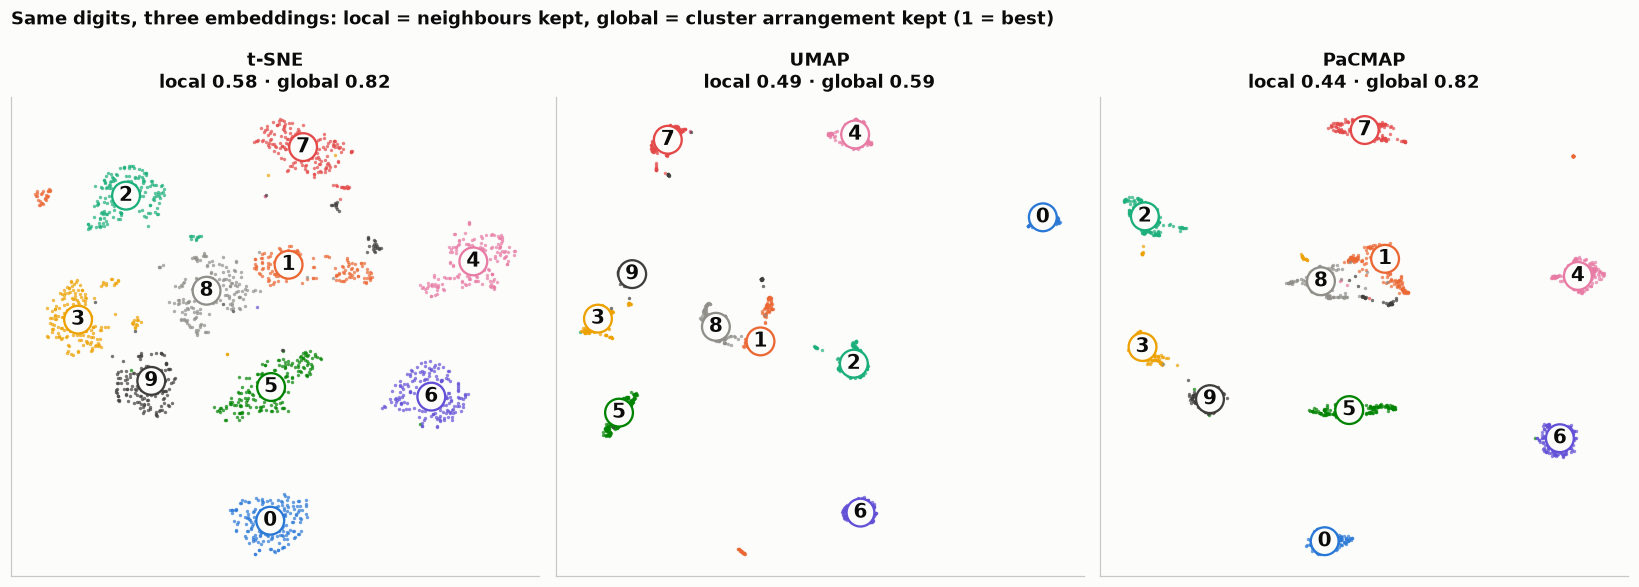

In [3]:
def local_score(high, low, k=10):
    nn_h = NearestNeighbors(n_neighbors=k + 1).fit(high).kneighbors(high, return_distance=False)[:, 1:]
    nn_l = NearestNeighbors(n_neighbors=k + 1).fit(low).kneighbors(low, return_distance=False)[:, 1:]
    return np.mean([len(set(a) & set(b)) / k for a, b in zip(nn_h, nn_l)])

def global_score(high, low, y):
    ch = np.array([high[y == c].mean(0) for c in range(10)])
    cl = np.array([low[y == c].mean(0) for c in range(10)])
    return spearmanr(pdist(ch), pdist(cl)).statistic

colors = PALETTE + ["#8f8e88", "#3f3e3b"]
fig, axes = plt.subplots(1, 3, figsize=(15, 5.4))
for ax, (name, emb) in zip(axes, embeddings.items()):
    for c in range(10):
        pts = emb[labels == c]
        ax.scatter(pts[:, 0], pts[:, 1], s=5, color=colors[c], alpha=0.7, linewidth=0)
        cx, cy = np.median(pts, axis=0)
        ax.text(cx, cy, str(c), ha="center", va="center", fontsize=13, fontweight="bold", color="#0b0b0b",
                bbox=dict(boxstyle="circle,pad=0.2", facecolor="#fcfcfb", edgecolor=colors[c], linewidth=1.5))
    ax.set_title(f"{name}\nlocal {local_score(X, emb):.2f} · global {global_score(X, emb, labels):.2f}",
                 loc="center", fontsize=12)
    ax.set_xticks([])
    ax.set_yticks([])
    ax.grid(False)
fig.suptitle("Same digits, three embeddings: local = neighbours kept, global = cluster arrangement kept (1 = best)",
             x=0.01, ha="left", fontsize=12, fontweight="bold")
fig.tight_layout()
plt.show()

## How to read it

All three separate the ten digits, so those clusters are real. They disagree on everything else. Here t-SNE keeps the most nearest neighbours and, with PaCMAP, the best cluster arrangement; UMAP packs each digit into a tight blob and scatters the blobs, keeping less of the global arrangement. Cluster size, spacing and position are artefacts of the method: read them only where the global score is high, and never read the empty space between clusters as a distance.

## Reference

This method comes from the research literature:

- Wang, Y., Huang, H., Rudin, C. & Shaposhnik, Y. (2021). Understanding how dimension reduction tools work: an empirical approach to deciphering t-SNE, UMAP, TriMap, and PaCMAP for data visualization. Journal of Machine Learning Research 22(201), 1–73. <https://jmlr.org/papers/v22/20-1061.html>

---
Standalone script: [`dimension_reduction_comparison.py`](dimension_reduction_comparison.py) &nbsp;·&nbsp; [Catalogue](../../README.md) &nbsp;·&nbsp; [Gallery](../../gallery/index.html)